In [ ]:

# EXPERIMENT 3 — MILESTONE 1, STEP 1

import subprocess
from pathlib import Path

# Define the GitHub project location
repo = Path("/content/register-feature-family")

# Download the project
if not repo.exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/Rinetta1981/register-feature-family.git",
        str(repo)
    ], check=True)

print("Project loaded successfully!")

# Find saved transformer models
checkpoints = [
    p for p in repo.rglob("*")
    if p.is_file()
    and p.suffix in (".pt", ".pth", ".ckpt", ".safetensors")
]

print("Trained model files found:", len(checkpoints))

for p in checkpoints:
    print(p.relative_to(repo))

print("Step 1 complete!")


Project loaded successfully!
Trained model files found: 1
artifacts/development-seed-0/model.pt
Step 1 complete!


In [ ]:

# EXPERIMENT 3 — STEP 2
# Train one development model

import sys
import subprocess
from pathlib import Path

repo = Path("/content/register-feature-family")

# Install the project's requirements
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-e", "."],
    cwd=str(repo),
    check=True
)

# Train the transformer using seed 0
subprocess.run(
    [
        sys.executable,
        "scripts/train_development_model.py",
        "0",
        "artifacts/development-seed-0"
    ],
    cwd=str(repo),
    check=True
)

# Show the saved files
output = repo / "artifacts/development-seed-0"

print("\nTraining completed!")
print("\nSaved files:")

for file in output.rglob("*"):
    if file.is_file():
        print(file.relative_to(repo))


Training completed!

Saved files:
artifacts/development-seed-0/metrics.json
artifacts/development-seed-0/model.pt


In [ ]:

# EXPERIMENT 3 — STEP 3
# Examine training results

import json
from pathlib import Path

metrics_file = Path(
    "/content/register-feature-family/artifacts/development-seed-0/metrics.json"
)

with open(metrics_file) as f:
    metrics = json.load(f)

print(json.dumps(metrics, indent=2))

{
  "best_validation_epoch": 79,
  "best_validation_loss": 0.00026993303866842516,
  "dataset_fingerprint": "ff1315604a48d991a97af8a1b8ba8749f5f9bff94614263a155d216c7770e8c7",
  "familiarization_final_loss": 0.0041257912913958234,
  "model_seed": 0,
  "parameter_count": 438272,
  "register_epochs_completed": 80,
  "source_revision": "local",
  "tokenizer_fingerprint": "f1cf46bd23a6b4870bfdfc4192cff98b7d7fc20706052c2a1aee9c278b793eef",
  "training_config": {
    "batch_size": 64,
    "early_stopping_min_delta": 1e-05,
    "early_stopping_patience": 12,
    "familiarization_epochs": 150,
    "gradient_clip_norm": 1.0,
    "learning_rate": 0.001,
    "minimum_register_epochs": 20,
    "register_epochs": 80,
    "weight_decay": 0.01
  },
  "validation_exact_match": 1.0
}


In [ ]:

# EXPERIMENT 3 — STEP 4 (CORRECTED)
# Load the model and examine its predictions

import sys
from pathlib import Path
import torch

# Fix the Python import path
repo = Path("/content/register-feature-family")
sys.path.insert(0, str(repo / "src"))

from register_feature_family.model import DecoderOnlyTransformer
from register_feature_family.tokenizer import ClosedVocabularyTokenizer
from register_feature_family.dataset_v02 import generate_confirmatory_records_v02
from register_feature_family.training import greedy_generate_target

# Load your trained transformer
model_path = repo / "artifacts/development-seed-0/model.pt"

checkpoint = torch.load(
    model_path,
    map_location="cpu",
    weights_only=True
)

model = DecoderOnlyTransformer()
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Model loaded successfully!")

# Load examples
tokenizer = ClosedVocabularyTokenizer()
records = generate_confirmatory_records_v02(seed=0)

# Examine familiar and unfamiliar examples
for split in ["iid_test", "compositional_ood_test"]:

    print("\nDATASET:", split)

    examples = [
        r for r in records if r.split.value == split
    ][:3]

    for i, record in enumerate(examples, 1):

        prediction = " ".join(
            greedy_generate_target(
                model=model,
                record=record,
                tokenizer=tokenizer
            )
        )

        print(f"\nExample {i}")
        print("Input:", record.context_text)
        print("Expected:", record.target_text)
        print("Predicted:", prediction)
        print("Correct:", prediction == record.target_text)

print("\nSTEP 4 COMPLETE!")

Model loaded successfully!

DATASET: iid_test

Example 1
Input: <REQ> <ROLE_01> <ROLE_03> <CONTENT_01> <RC1_0> <RC2_0> <RC3_0>
Expected: rume daru
Predicted: rume daru
Correct: True

Example 2
Input: <REQ> <ROLE_01> <ROLE_03> <CONTENT_01> <RC1_0> <RC2_1> <RC3_1>
Expected: mira rume daru
Predicted: mira rume daru
Correct: True

Example 3
Input: <REQ> <ROLE_01> <ROLE_03> <CONTENT_01> <RC1_1> <RC2_1> <RC3_1>
Expected: kelo rume daru
Predicted: kelo rume daru
Correct: True

DATASET: compositional_ood_test

Example 1
Input: <REQ> <ROLE_01> <ROLE_01> <CONTENT_01> <RC1_1> <RC2_0> <RC3_0>
Expected: kelo mira rume daru
Predicted: rume daru
Correct: False

Example 2
Input: <REQ> <ROLE_01> <ROLE_01> <CONTENT_01> <RC1_1> <RC2_0> <RC3_1>
Expected: muki daru
Predicted: kelo kelo muki daru
Correct: False

Example 3
Input: <REQ> <ROLE_01> <ROLE_02> <CONTENT_01> <RC1_1> <RC2_0> <RC3_0>
Expected: kelo mira rume daru
Predicted: rume daru
Correct: False

STEP 4 COMPLETE!


In [ ]:

# EXPERIMENT 3 — STEP 5
# Patch internal activations in your own transformer

import torch
import pandas as pd
from IPython.display import display

from register_feature_family.tokenizer import BOS_TOKEN, SEP_TOKEN

model.eval()

# Find an unfamiliar example with an incorrect first token,
# and a familiar example with the same meaning and roles.
pair = None

for candidate in records:
    if candidate.split.value != "compositional_ood_test":
        continue

    donors = [
        r for r in records
        if r.comparison_group_id == candidate.comparison_group_id
        and r.split.value in ("train", "validation", "iid_test")
        and r.target_text.split()[0] == candidate.target_text.split()[0]
    ]

    if not donors:
        continue

    prefix = [BOS_TOKEN, *candidate.context_text.split(), SEP_TOKEN]
    ids = torch.tensor([tokenizer.encode_tokens(prefix)])

    with torch.no_grad():
        predicted_id = model(ids)[0, -1].argmax().item()

    expected_id = tokenizer.token_id(candidate.target_text.split()[0])

    if predicted_id != expected_id:
        pair = (candidate, donors[0])
        break

if pair is None:
    raise RuntimeError("No suitable example pair found.")

ood, donor = pair

def encode(record):
    tokens = [BOS_TOKEN, *record.context_text.split(), SEP_TOKEN]
    return torch.tensor([tokenizer.encode_tokens(tokens)])

ood_ids = encode(ood)
donor_ids = encode(donor)

assert ood_ids.shape == donor_ids.shape

expected_id = tokenizer.token_id(ood.target_text.split()[0])

with torch.no_grad():
    baseline = model(ood_ids)[0, -1].clone()

wrong_id = baseline.argmax().item()

def margin(logits):
    return (logits[expected_id] - logits[wrong_id]).item()

print("OOD input:", ood.context_text)
print("Familiar donor:", donor.context_text)
print("Expected first token:", tokenizer.token_for_id(expected_id))
print("Original prediction:", tokenizer.token_for_id(wrong_id))
print("Baseline margin:", round(margin(baseline), 3))

results = []

for layer in range(model.config.n_layers):
    for component_name in ("attention", "mlp"):

        component = getattr(model.blocks[layer], component_name)
        cache = {}

        # Record the familiar example's activation
        def capture(module, inputs, output):
            cache["activation"] = output.detach().clone()

        hook = component.register_forward_hook(capture)
        try:
            with torch.no_grad():
                model(donor_ids)
        finally:
            hook.remove()

        # Insert that activation into the unfamiliar example
        def patch(module, inputs, output):
            changed = output.clone()
            changed[:, -1, :] = cache["activation"][:, -1, :]
            return changed

        hook = component.register_forward_hook(patch)
        try:
            with torch.no_grad():
                patched_logits = model(ood_ids)[0, -1].clone()
        finally:
            hook.remove()

        results.append({
            "layer": layer,
            "component": component_name,
            "original_margin": round(margin(baseline), 3),
            "patched_margin": round(margin(patched_logits), 3),
            "change": round(
                margin(patched_logits) - margin(baseline), 3
            ),
            "predicted_token": tokenizer.token_for_id(
                patched_logits.argmax().item()
            )
        })

df = pd.DataFrame(results)
display(df)

print("\nStep 5 complete!")
print("Exploratory intervention only; controls come next.")

OOD input: <REQ> <ROLE_01> <ROLE_01> <CONTENT_01> <RC1_1> <RC2_0> <RC3_0>
Familiar donor: <REQ> <ROLE_01> <ROLE_01> <CONTENT_01> <RC1_1> <RC2_1> <RC3_1>
Expected first token: kelo
Original prediction: rume
Baseline margin: -1.338


,layer,component,original_margin,patched_margin,change,predicted_token
0,0,attention,-1.338,11.077,12.416,kelo
1,0,mlp,-1.338,3.564,4.903,kelo
2,1,attention,-1.338,5.071,6.410,kelo
3,1,mlp,-1.338,5.795,7.133,kelo



Step 5 complete!
Exploratory intervention only; controls come next.


In [ ]:

# EXPERIMENT 3 — STEP 6
# Test the causal intervention with controls

import torch
import pandas as pd
from IPython.display import display

model.eval()

# Find a familiar example with a different target word
candidates = [
    r for r in records
    if r.split.value in ("train", "validation", "iid_test")
    and len(r.context_text.split()) == len(ood.context_text.split())
    and r.target_text.split()[0] != ood.target_text.split()[0]
]

if not candidates:
    raise RuntimeError("No suitable comparison donor found.")

# Prefer examples with similar input contexts
candidates.sort(
    key=lambda r: sum(
        a == b for a, b in zip(
            r.context_text.split(),
            ood.context_text.split()
        )
    ),
    reverse=True
)

different_donor = candidates[0]
different_ids = encode(different_donor)

print("Original OOD input:", ood.context_text)
print("Original expected word:", ood.target_text.split()[0])
print("Targeted donor:", donor.context_text)
print("Different donor:", different_donor.context_text)
print("Different donor's target:",
      different_donor.target_text.split()[0])

# Save an internal activation
def capture_activation(component, tokens):
    saved = {}

    def capture(module, inputs, output):
        saved["activation"] = output.detach().clone()

    hook = component.register_forward_hook(capture)
    try:
        with torch.no_grad():
            model(tokens)
    finally:
        hook.remove()

    return saved["activation"]

# Replace the activation and measure the output
def run_intervention(component, activation):
    def patch(module, inputs, output):
        changed = output.clone()
        changed[:, -1, :] = activation[:, -1, :]
        return changed

    hook = component.register_forward_hook(patch)
    try:
        with torch.no_grad():
            logits = model(ood_ids)[0, -1].clone()
    finally:
        hook.remove()

    return logits

rows = []

for layer in range(model.config.n_layers):
    for name in ("attention", "mlp"):

        component = getattr(model.blocks[layer], name)

        targeted = capture_activation(component, donor_ids)
        same_input = capture_activation(component, ood_ids)
        different = capture_activation(component, different_ids)

        targeted_logits = run_intervention(component, targeted)
        sham_logits = run_intervention(component, same_input)
        different_logits = run_intervention(component, different)

        rows.append({
            "layer": layer,
            "component": name,
            "targeted_change": round(
                margin(targeted_logits) - margin(baseline), 3
            ),
            "sham_change": round(
                margin(sham_logits) - margin(baseline), 3
            ),
            "different_donor_change": round(
                margin(different_logits) - margin(baseline), 3
            ),
            "different_donor_prediction":
                tokenizer.token_for_id(
                    different_logits.argmax().item()
                )
        })

controls_df = pd.DataFrame(rows)
display(controls_df)

# Save results
folder = repo / "artifacts" / "causal_followup"
folder.mkdir(parents=True, exist_ok=True)
controls_df.to_csv(folder / "controls.csv", index=False)

print("\nStep 6 complete!")
print("Results saved to:", folder / "controls.csv")

Original OOD input: <REQ> <ROLE_01> <ROLE_01> <CONTENT_01> <RC1_1> <RC2_0> <RC3_0>
Original expected word: kelo
Targeted donor: <REQ> <ROLE_01> <ROLE_01> <CONTENT_01> <RC1_1> <RC2_1> <RC3_1>
Different donor: <REQ> <ROLE_01> <ROLE_01> <CONTENT_01> <RC1_0> <RC2_0> <RC3_0>
Different donor's target: rume


,layer,component,targeted_change,sham_change,different_donor_change,different_donor_prediction
0,0,attention,12.416,0.0,-7.896,rume
1,0,mlp,4.903,0.0,-0.960,rume
2,1,attention,6.410,0.0,-4.770,rume
3,1,mlp,7.133,0.0,-4.538,rume



Step 6 complete!
Results saved to: /content/register-feature-family/artifacts/causal_followup/controls.csv


,layer,component,examples,mean_targeted_change,mean_other_change,max_sham_error,fraction_correct
0,0,attention,12,13.712,-7.632,0.0,1.0
1,0,mlp,12,8.399,-1.297,0.0,1.0
2,1,attention,12,8.022,-5.174,0.0,1.0
3,1,mlp,12,8.540,-4.733,0.0,1.0


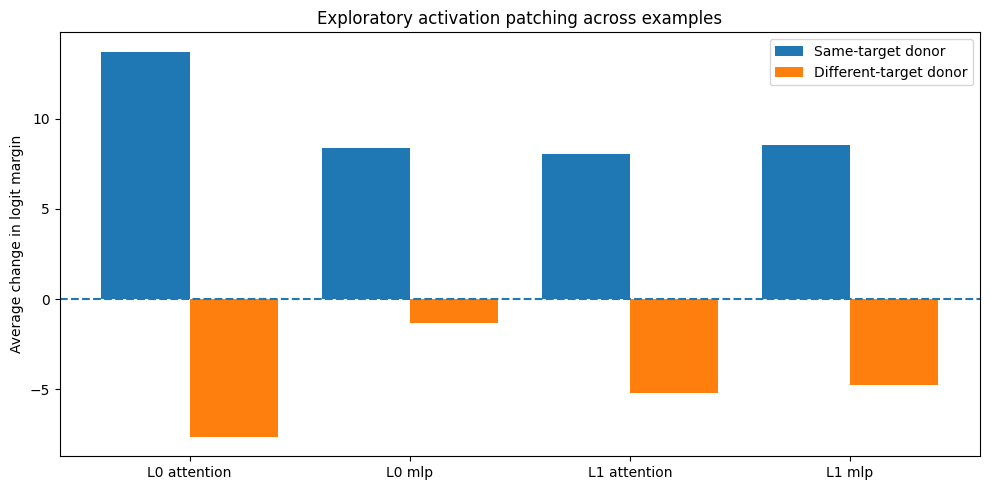

Examples tested: 12
Maximum sham error: 0.0
STEP 7 COMPLETE!


In [ ]:
# EXPERIMENT 3 — STEP 7
# Repeat the intervention across multiple examples

import torch
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

model.eval()

def patch_from(component, target_ids, source_ids):
    saved = {}

    def capture(module, inputs, output):
        saved["activation"] = output.detach().clone()

    hook = component.register_forward_hook(capture)
    try:
        with torch.no_grad():
            model(source_ids)
    finally:
        hook.remove()

    def patch(module, inputs, output):
        changed = output.clone()
        changed[:, -1, :] = saved["activation"][:, -1, :]
        return changed

    hook = component.register_forward_hook(patch)
    try:
        with torch.no_grad():
            result = model(target_ids)[0, -1].clone()
    finally:
        hook.remove()

    return result

familiar = [
    r for r in records
    if r.split.value in ("train", "validation", "iid_test")
]

rows = []
used_contents = set()

for target in records:

    if target.split.value != "compositional_ood_test":
        continue
    if target.content_id in used_contents:
        continue

    donors = [
        r for r in familiar
        if r.comparison_group_id == target.comparison_group_id
    ]

    expected_word = target.target_text.split()[0]

    same = next(
        (r for r in donors
         if r.target_text.split()[0] == expected_word),
        None
    )

    different = next(
        (r for r in donors
         if r.target_text.split()[0] != expected_word),
        None
    )

    if same is None or different is None:
        continue

    target_ids = encode(target)

    with torch.no_grad():
        baseline_logits = model(target_ids)[0, -1]

    expected_id = tokenizer.token_id(expected_word)
    wrong_id = baseline_logits.argmax().item()

    if expected_id == wrong_id:
        continue

    used_contents.add(target.content_id)

    def score(logits):
        return (
            logits[expected_id] - logits[wrong_id]
        ).item()

    baseline_score = score(baseline_logits)

    for layer in range(model.config.n_layers):
        for name in ("attention", "mlp"):

            component = getattr(model.blocks[layer], name)

            good_logits = patch_from(
                component, target_ids, encode(same)
            )

            other_logits = patch_from(
                component, target_ids, encode(different)
            )

            sham_logits = patch_from(
                component, target_ids, target_ids
            )

            rows.append({
                "example": target.example_id,
                "layer": layer,
                "component": name,
                "same_target_change":
                    score(good_logits) - baseline_score,
                "different_target_change":
                    score(other_logits) - baseline_score,
                "sham_change":
                    score(sham_logits) - baseline_score,
                "correct_after_patch":
                    int(good_logits.argmax().item() == expected_id)
            })

    if len(used_contents) >= 12:
        break

if not rows:
    raise RuntimeError("No eligible examples found.")

df_multi = pd.DataFrame(rows)

summary = df_multi.groupby(
    ["layer", "component"], as_index=False
).agg(
    examples=("example", "count"),
    mean_targeted_change=("same_target_change", "mean"),
    mean_other_change=("different_target_change", "mean"),
    max_sham_error=("sham_change", lambda x: x.abs().max()),
    fraction_correct=("correct_after_patch", "mean")
)

display(summary.round(3))

folder = Path(
    "/content/register-feature-family/artifacts/causal_followup"
)
folder.mkdir(parents=True, exist_ok=True)

df_multi.to_csv(folder / "multi_example_results.csv", index=False)
summary.to_csv(folder / "multi_example_summary.csv", index=False)

# Graph
labels = [
    f"L{r.layer} {r.component}"
    for r in summary.itertuples()
]

x = list(range(len(labels)))

plt.figure(figsize=(10, 5))
plt.bar(
    [i - 0.2 for i in x],
    summary["mean_targeted_change"],
    width=0.4,
    label="Same-target donor"
)
plt.bar(
    [i + 0.2 for i in x],
    summary["mean_other_change"],
    width=0.4,
    label="Different-target donor"
)

plt.xticks(x, labels)
plt.axhline(0, linestyle="--")
plt.ylabel("Average change in logit margin")
plt.title("Exploratory activation patching across examples")
plt.legend()
plt.tight_layout()

plt.savefig(folder / "multi_example_graph.png", dpi=160)
plt.show()

print("Examples tested:", len(used_contents))
print("Maximum sham error:", df_multi.sham_change.abs().max())
print("STEP 7 COMPLETE!")

In [ ]:
# EXPERIMENT 3 — STEP 8
# Prepare the research report and download results

from pathlib import Path
import shutil
from google.colab import files

folder = Path(
    "/content/register-feature-family/artifacts/causal_followup"
)

# Build the results table automatically
table = [
    "| Layer | Component | Mean change | Correct first word |",
    "|---|---|---:|---:|"
]

for row in summary.itertuples():
    table.append(
        f"| {row.layer} | {row.component} | "
        f"{row.mean_targeted_change:+.3f} | "
        f"{row.fraction_correct:.0%} |"
    )

report = f"""# Experiment 3: Causal Interventions in Register Generalization

## Research Question

How do internal transformer activations influence predictions
on unfamiliar linguistic-register combinations?

## Model

- Custom 438,272-parameter transformer
- Two transformer layers
- Training seed: 0
- Original project: Register Feature Family

## Method

We selected 12 previously exposed out-of-distribution
examples with incorrect first-token predictions.

For each example, we replaced internal activations with
activations from familiar donor examples.

We compared attention and MLP components across two layers.

Controls included:
- Same-input (sham) interventions
- Donors with different expected first tokens

## Results

{chr(10).join(table)}

Sham interventions produced zero change.

Different-target donors generally moved the prediction
margin in the opposite direction.

## Interpretation

Donor-dependent interventions causally influenced
the model's first-token predictions.

However, these results do not establish a specific
mechanism for register-generalization failure.

## Limitations

- Exploratory analysis of 12 selected examples
- Only one trained model seed
- Previously exposed test examples
- Donors selected partly by expected target token
- First-token predictions only
- No identification of individual attention heads or circuits
- No independent replication or confidence intervals

## Conclusion

The experiment demonstrates reproducible intervention
effects in the tested model run.

Further controlled experiments are needed to distinguish
register-specific mechanisms from donor-answer transfer.

## Related Research

https://github.com/Rinetta1981/register-feature-family
"""

(folder / "REPORT.md").write_text(report, encoding="utf-8")

# Include training information
metrics_file = Path(
    "/content/register-feature-family/artifacts/development-seed-0/metrics.json"
)

shutil.copy2(metrics_file, folder / "training_metrics.json")

# Package results
zip_file = shutil.make_archive(
    "/content/experiment3_causal_followup",
    "zip",
    root_dir=str(folder.parent),
    base_dir=folder.name
)

print("Research report created!")
print("Files packaged successfully!")

files.download(zip_file)


Research report created!
Files packaged successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>